In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving NLP_Preprocessed_Dataset.xlsx to NLP_Preprocessed_Dataset.xlsx


In [3]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_excel(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (3200, 14)


,id,text,topic,label,source_type,source_reference,reason,final_label,normalized_text,tokens,token_count,tokens_no_stopwords,nlp_text,nlp_text_no_stopwords
0,TAM0001,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,Seeds,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,"['విత్తనాలను', 'సరైన', 'తేమ', 'ఉన్న', 'ప్రదేశం...",7,"['విత్తనాలను', 'సరైన', 'తేమ', 'ఉన్న', 'ప్రదేశం...",విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి
1,TAM0002,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,Fertilizers,MISINFORMATION,Self-created candidate dataset,NaN,"Unverified, exaggerated or absolute claim",MISINFORMATION,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,"['వ్యవసాయ', 'సమాచారం', 'ఈ', 'ఎరువు', 'అన్ని', ...",10,"['వ్యవసాయ', 'సమాచారం', 'ఎరువు', 'అన్ని', 'నేల'...",వ్యవసాయ సమాచారం ఈ ఎరువు అన్ని నేల సమస్యలను ఒక్...,వ్యవసాయ సమాచారం ఎరువు అన్ని నేల సమస్యలను ఒక్క ...
2,TAM0003,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,Pesticides,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,"['రైతులకు', 'సమాచారం', 'పురుగుమందును', 'లేబుల్...",12,"['రైతులకు', 'సమాచారం', 'పురుగుమందును', 'లేబుల్...",రైతులకు సమాచారం పురుగుమందును లేబుల్ సూచనల ప్రక...,రైతులకు సమాచారం పురుగుమందును లేబుల్ సూచనల ప్రక...
3,TAM0004,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,Crop Diseases,MISINFORMATION,Self-created candidate dataset,NaN,"Unverified, exaggerated or absolute claim",MISINFORMATION,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,"['ఈ', 'మందు', 'అన్ని', 'పంట', 'వ్యాధులను', 'ఒక...",14,"['మందు', 'అన్ని', 'పంట', 'వ్యాధులను', 'ఒక్క', ...",ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస్త...
4,TAM0005,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,Irrigation,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,"['పంట', 'ఎదుగుదల', 'దశను', 'బట్టి', 'నీటి', 'అ...",7,"['పంట', 'ఎదుగుదల', 'దశను', 'బట్టి', 'నీటి', 'అ...",పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...


In [4]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Columns:
['id', 'text', 'topic', 'label', 'source_type', 'source_reference', 'reason', 'final_label', 'normalized_text', 'tokens', 'token_count', 'tokens_no_stopwords', 'nlp_text', 'nlp_text_no_stopwords']

Missing Values:
id                          0
text                        0
topic                       0
label                       0
source_type                 0
source_reference         3200
reason                      0
final_label                 0
normalized_text             0
tokens                      0
token_count                 0
tokens_no_stopwords         0
nlp_text                    0
nlp_text_no_stopwords       0
dtype: int64


In [5]:
X = df["nlp_text"].fillna("").astype(str)

y = df["label"].astype(str)

print("Input Text:")
display(X.head())

print("\nLabel Distribution:")
print(y.value_counts())

Input Text:


,nlp_text
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి
1,వ్యవసాయ సమాచారం ఈ ఎరువు అన్ని నేల సమస్యలను ఒక్...
2,రైతులకు సమాచారం పురుగుమందును లేబుల్ సూచనల ప్రక...
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...



Label Distribution:
label
INFORMATION       1600
MISINFORMATION    1600
Name: count, dtype: int64


In [6]:
print("Total Records:", len(df))

print("Missing Text:", X.isna().sum())

print("Empty Text:", (X.str.strip() == "").sum())

print("Missing Labels:", y.isna().sum())

print("\nUnique Labels:")
print(y.unique())

Total Records: 3200
Missing Text: 0
Empty Text: 0
Missing Labels: 0

Unique Labels:
['INFORMATION' 'MISINFORMATION']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed!")

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Training Percentage:",
      len(X_train) / len(X) * 100)

print("Testing Percentage:",
      len(X_test) / len(X) * 100)

Train-Test Split Completed!
Training Records: 2560
Testing Records: 640
Training Percentage: 80.0
Testing Percentage: 20.0


In [8]:
# Create TF-IDF vectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 2),
    max_features=10000
)

# Fit only on training text
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing text
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF Vectorization Completed!")

print("Training Feature Shape:",
      X_train_tfidf.shape)

print("Testing Feature Shape:",
      X_test_tfidf.shape)

TF-IDF Vectorization Completed!
Training Feature Shape: (2560, 632)
Testing Feature Shape: (640, 632)


In [9]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 50 Features:")

print(feature_names[:50])

Total Features: 632

First 50 Features:
['100' '100 బస' 'అ' 'అ త' 'అన' 'అన ఒక' 'అన క' 'అన గ' 'అన న' 'అయ' 'అయ న'
 'అవ' 'అవ త' 'అవసర' 'అవసర ఉ' 'అవసర న' 'అవసర ప' 'అవసర ల' 'ఆధ' 'ఆధ రపడ' 'ఆర'
 'ఆర గ' 'ఇ' 'ఇ ట' 'ఇస' 'ఇస త' 'ఈ' 'ఈ ఎర' 'ఈ ఒక' 'ఈ ట' 'ఈ ప' 'ఈ పద' 'ఈ మ'
 'ఈ య' 'ఈ ల' 'ఉ' 'ఉ ట' 'ఉ డద' 'ఉత' 'ఉత పత' 'ఉధ' 'ఉధ త' 'ఉన' 'ఉన న' 'ఉపయ'
 'ఉపయ గ' 'ఉపయ గకర' 'ఉపయ గపడ' 'ఉష' 'ఉష ణ']


In [10]:
# Display first 5 training records

sample_features = X_train_tfidf[:5].toarray()

feature_df = pd.DataFrame(
    sample_features,
    columns=feature_names
)

display(feature_df.iloc[:, :20])

,100,100 బస,అ,అ త,అన,అన ఒక,అన క,అన గ,అన న,అయ,అయ న,అవ,అవ త,అవసర,అవసర ఉ,అవసర న,అవసర ప,అవసర ల,ఆధ,ఆధ రపడ
0,0.0,0.0,0.0,0.0,0.128923,0.069476,0.0,0.0,0.134809,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.051719,0.055742,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.052320,0.056390,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.112462,0.060605,0.0,0.0,0.117597,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
print("Training Matrix Shape:", X_train_tfidf.shape)

print("Testing Matrix Shape:", X_test_tfidf.shape)

print("Training Matrix Data Type:",
      X_train_tfidf.dtype)

print("Training Matrix Non-Zero Values:",
      X_train_tfidf.nnz)

print("Training Matrix Density:",
      X_train_tfidf.nnz /
      (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]))

Training Matrix Shape: (2560, 632)
Testing Matrix Shape: (640, 632)
Training Matrix Data Type: float64
Training Matrix Non-Zero Values: 136437
Training Matrix Density: 0.08432864418512659


/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3116 (\N{TELUGU LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3077 (\N{TELUGU LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3108 (\N{TELUGU LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserWarning: Glyph 3090 (\N{TELUGU LETTER O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1778/894585094.py:18: UserW

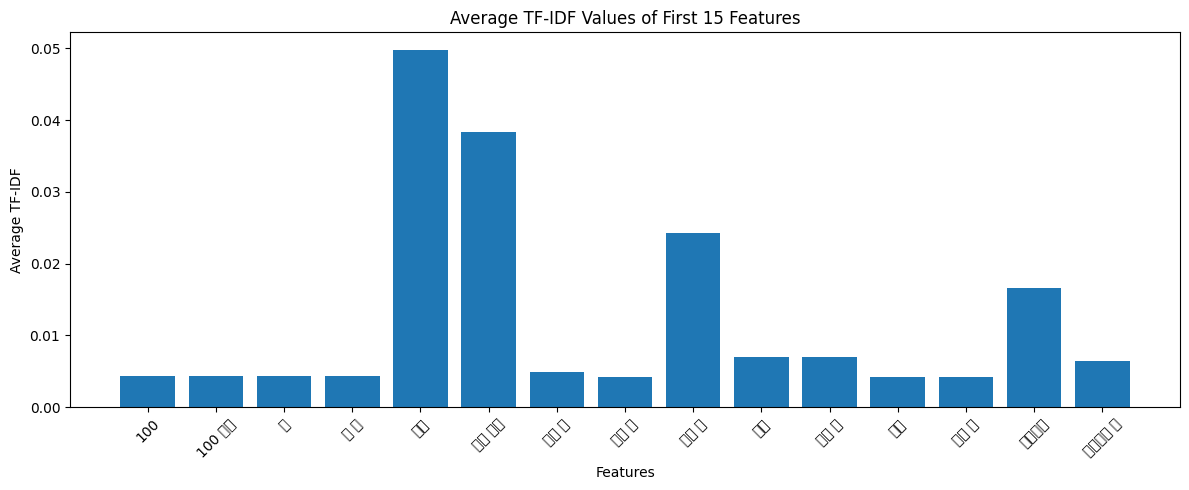

In [12]:
# Select first 15 features
top_features = feature_names[:15]

# Calculate average TF-IDF values
feature_values = np.asarray(
    X_train_tfidf[:, :15].mean(axis=0)
).ravel()

plt.figure(figsize=(12, 5))

plt.bar(top_features, feature_values)

plt.title("Average TF-IDF Values of First 15 Features")
plt.xlabel("Features")
plt.ylabel("Average TF-IDF")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
import pickle

with open("TFIDF_Vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf_vectorizer, file)

print("TF-IDF Vectorizer Saved Successfully!")

TF-IDF Vectorizer Saved Successfully!


In [14]:
from scipy.sparse import save_npz

save_npz("X_train_tfidf.npz", X_train_tfidf)

save_npz("X_test_tfidf.npz", X_test_tfidf)

print("TF-IDF Feature Matrices Saved!")

TF-IDF Feature Matrices Saved!


In [15]:
y_train.to_csv("y_train.csv", index=False)

y_test.to_csv("y_test.csv", index=False)

print("Training and Testing Labels Saved!")

Training and Testing Labels Saved!


In [16]:
vocabulary_df = pd.DataFrame({
    "Feature_Index": range(len(feature_names)),
    "Feature": feature_names
})

vocabulary_df.to_csv(
    "TFIDF_Vocabulary.csv",
    index=False,
    encoding="utf-8-sig"
)

display(vocabulary_df.head(20))

print("Vocabulary Saved Successfully!")

,Feature_Index,Feature
0,0,100
1,1,100 బస
2,2,అ
3,3,అ త
4,4,అన
5,5,అన ఒక
6,6,అన క
7,7,అన గ
8,8,అన న
9,9,అయ


Vocabulary Saved Successfully!


In [17]:
from google.colab import files

files.download("TFIDF_Vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
files.download("X_train_tfidf.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
files.download("X_test_tfidf.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
files.download("y_train.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
files.download("y_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
files.download("TFIDF_Vocabulary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print("STEP 6: TF-IDF FEATURE EXTRACTION")

print("--------------------------------")

print("Original Dataset:", df.shape)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("Training TF-IDF Shape:", X_train_tfidf.shape)

print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("Total TF-IDF Features:", len(feature_names))

print("--------------------------------")

print("STEP 6 COMPLETED SUCCESSFULLY!")

STEP 6: TF-IDF FEATURE EXTRACTION
--------------------------------
Original Dataset: (3200, 14)
Training Records: 2560
Testing Records: 640
Training TF-IDF Shape: (2560, 632)
Testing TF-IDF Shape: (640, 632)
Total TF-IDF Features: 632
--------------------------------
STEP 6 COMPLETED SUCCESSFULLY!
